<center><h1>Li_Wenxin_HW5</h1></center>
<br>
<br>

Name: Wenxin Li
<br>
Github Username: Wendyllli
<br>
USC ID: 1269534541

## 1. Decision Trees as Interpretable Models

Import packages

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import KFold, StratifiedKFold, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, mean_squared_error
from xgboost import XGBRegressor

DATA = Path("data")
cv = KFold(n_splits=5, shuffle=True, random_state=552)
pd.set_option("display.max_rows", 130)
sns.set_theme(style="whitegrid")

### (a) Obtain Data

Get the Accute Inamations Data Set

I use the provided Acute Inflammations data. yes = 1 and no = 0.
I combine the two diagnosis labels into four classes (label powerset):
0 = neither, 1 = nephritis only, 2 = bladder inflammation only, 3 = both.

In [3]:
symptoms = ["temperature", "nausea", "lumbar_pain", "urine_pushing",
            "micturition_pain", "burning"]
diagnosis = pd.read_csv(DATA / "diagnosis.data", sep="\t", decimal=",",
                        encoding="utf-16", header=None,
                        names=symptoms + ["bladder", "nephritis"])
diagnosis = diagnosis.replace({"yes": 1, "no": 0}).astype(float)
X_tree = diagnosis[symptoms]
y_tree = (2 * diagnosis["bladder"] + diagnosis["nephritis"]).astype(int)
class_names = ["Neither", "Nephritis only", "Bladder only", "Both"]
print("Shape:", diagnosis.shape)
print("Missing values:", diagnosis.isna().sum().sum())
display(y_tree.value_counts().sort_index().rename("count").to_frame())
display(diagnosis.head())

Shape: (120, 8)
Missing values: 0


,count
0,30
1,31
2,40
3,19


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pain,burning,bladder,nephritis
0,35.5,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,35.9,0.0,0.0,1.0,1.0,1.0,1.0,0.0
2,35.9,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,36.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0
4,36.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


### (b) Build a decision tree

I fit the tree on all 120 observations, as requested. Its accuracy below is training accuracy.

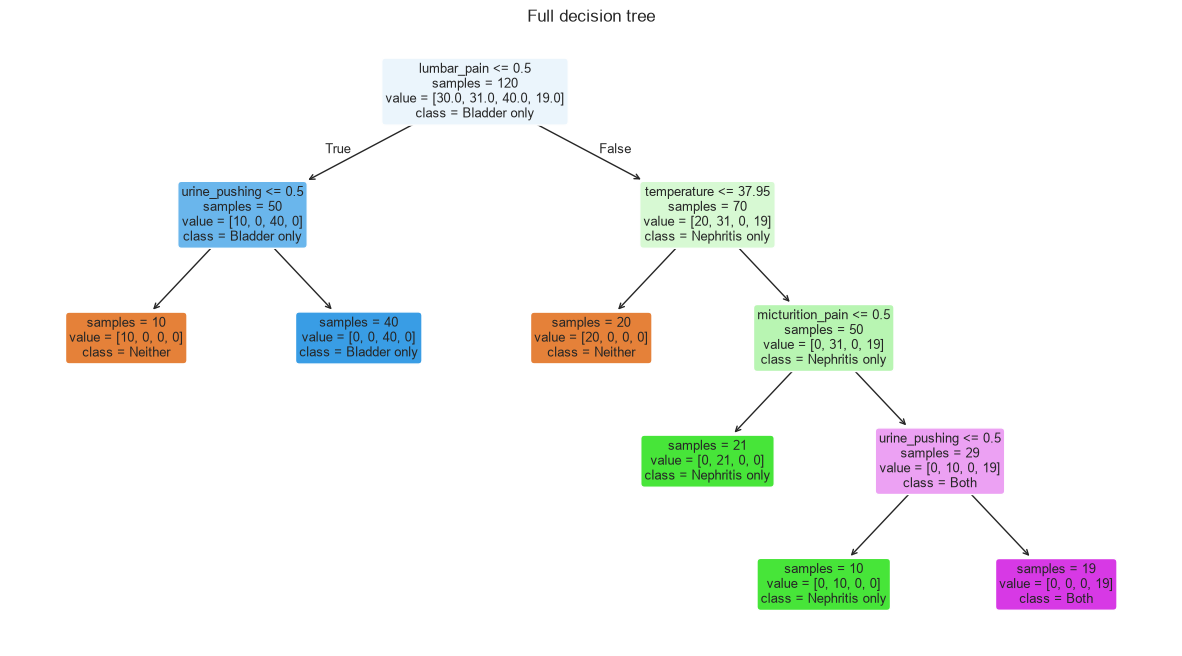

Depth: 4 Leaves: 6
Training accuracy: 1.0


In [4]:
tree = DecisionTreeClassifier(random_state=552)
tree.fit(X_tree, y_tree)
plt.figure(figsize=(15, 8))
plot_tree(tree, feature_names=symptoms, class_names=class_names,
          filled=True, rounded=True, impurity=False, fontsize=9)
plt.title("Full decision tree")
plt.show()
print("Depth:", tree.get_depth(), "Leaves:", tree.get_n_leaves())
print("Training accuracy:", accuracy_score(y_tree, tree.predict(X_tree)))

### (c) Convert the decision rules

In [5]:
def print_rules(model):
    t = model.tree_
    def walk(node, conditions):
        if t.children_left[node] == t.children_right[node]:
            label = model.classes_[t.value[node][0].argmax()]
            print("IF " + " AND ".join(conditions) + " THEN " + class_names[label])
            return
        feature = symptoms[t.feature[node]]
        cut = t.threshold[node]
        walk(t.children_left[node], conditions + [f"{feature} <= {cut:.2f}"])
        walk(t.children_right[node], conditions + [f"{feature} > {cut:.2f}"])
    walk(0, [])

print_rules(tree)

IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN Neither
IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN Bladder only
IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN Neither
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pain <= 0.50 THEN Nephritis only
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pain > 0.50 AND urine_pushing <= 0.50 THEN Nephritis only
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pain > 0.50 AND urine_pushing > 0.50 THEN Both


### (d) Cost-complexity pruning
I tune `ccp_alpha` with stratified five-fold CV. Choosing the largest alpha whose
mean accuracy is within one standard error of the best score. This favors a small,
readable subtree. The minimum is relative to the candidate subtrees, not all possible trees.

The path below shows how cost-complexity pruning reduces the full tree.

,alpha,leaves,train_accuracy
0,0.000000,6,1.000000
1,0.098167,4,0.841667
2,0.133333,3,0.758333
3,0.182000,2,0.591667
4,0.222917,1,0.333333


Chosen alpha: 0.088
CV accuracy: 0.9916666666666668
Depth: 4 Leaves: 6
Training accuracy: 1.0


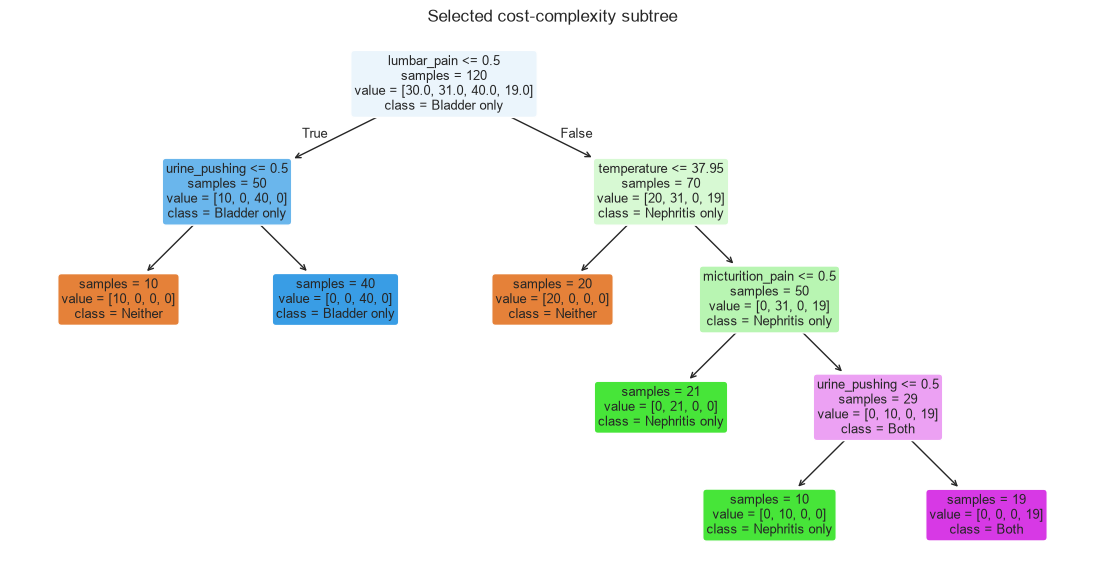

IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN Neither
IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN Bladder only
IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN Neither
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pain <= 0.50 THEN Nephritis only
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pain > 0.50 AND urine_pushing <= 0.50 THEN Nephritis only
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pain > 0.50 AND urine_pushing > 0.50 THEN Both


In [6]:
path = tree.cost_complexity_pruning_path(X_tree, y_tree)
path_rows = []
for alpha in path.ccp_alphas:
    model = DecisionTreeClassifier(ccp_alpha=alpha, random_state=552)
    model.fit(X_tree, y_tree)
    path_rows.append([alpha, model.get_n_leaves(),
                      accuracy_score(y_tree, model.predict(X_tree))])
display(pd.DataFrame(path_rows, columns=["alpha", "leaves", "train_accuracy"]))

tree_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=552)
prune_search = GridSearchCV(DecisionTreeClassifier(random_state=552),
    {"ccp_alpha": np.linspace(0, 0.3, 151)}, cv=tree_cv, scoring="accuracy")
prune_search.fit(X_tree, y_tree)
scores = prune_search.cv_results_
best = prune_search.best_index_
cutoff = scores["mean_test_score"][best] - scores["std_test_score"][best] / np.sqrt(5)
eligible = np.flatnonzero(scores["mean_test_score"] >= cutoff - 1e-12)
chosen = eligible[-1]
prune_alpha = scores["param_ccp_alpha"][chosen]
pruned = DecisionTreeClassifier(ccp_alpha=prune_alpha, random_state=552)
pruned.fit(X_tree, y_tree)
print("Chosen alpha:", prune_alpha)
print("CV accuracy:", scores["mean_test_score"][chosen])
print("Depth:", pruned.get_depth(), "Leaves:", pruned.get_n_leaves())
print("Training accuracy:", accuracy_score(y_tree, pruned.predict(X_tree)))
plt.figure(figsize=(14, 7))
plot_tree(pruned, feature_names=symptoms, class_names=class_names,
          filled=True, rounded=True, impurity=False, fontsize=9)
plt.title("Selected cost-complexity subtree")
plt.show()
print_rules(pruned)

The selected alpha is 0.088. CV accuracy is 99.17%, and training accuracy is
100%. The selected tree still has six leaves: further pruning is not supported
by the one-standard-error rule. The next subtree has four leaves and training
accuracy of 84.17%. I show its simpler rules below; it loses the separate Both
prediction, so I prefer the six-leaf tree for accuracy.

Simpler alternative: alpha = 0.1
Depth: 2 Leaves: 4
Training accuracy: 0.8416666666666667


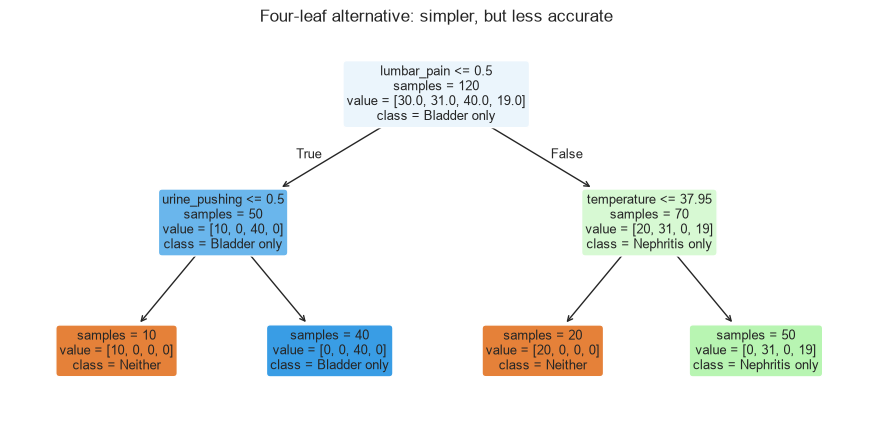

IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN Neither
IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN Bladder only
IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN Neither
IF lumbar_pain > 0.50 AND temperature > 37.95 THEN Nephritis only


In [7]:
simple = DecisionTreeClassifier(ccp_alpha=0.1, random_state=552)
simple.fit(X_tree, y_tree)
print("Simpler alternative: alpha = 0.1")
print("Depth:", simple.get_depth(), "Leaves:", simple.get_n_leaves())
print("Training accuracy:", accuracy_score(y_tree, simple.predict(X_tree)))
plt.figure(figsize=(11, 5))
plot_tree(simple, feature_names=symptoms, class_names=class_names,
          filled=True, rounded=True, impurity=False, fontsize=9)
plt.title("Four-leaf alternative: simpler, but less accurate")
plt.show()
print_rules(simple)

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [8]:
names = [line.split()[1] for line in (DATA / "communities.names").read_text().splitlines()
         if line.lower().startswith("@attribute")]
crime = pd.read_csv(DATA / "communities.data", header=None, names=names, na_values="?")
target = "ViolentCrimesPerPop"
nonpredictive = ["state", "county", "community", "communityname", "fold"]
X = crime.drop(columns=nonpredictive + [target])
y = crime[target]
X_train, X_test = X.iloc[:1495], X.iloc[1495:]
y_train, y_test = y.iloc[:1495], y.iloc[1495:]
print("Training:", X_train.shape, "Test:", X_test.shape)
print("Missing targets:", y.isna().sum())

Training: (1495, 122) Test: (499, 122)
Missing targets: 0


### (b) Missing values

All 122 predictors are kept.
The completed training data below are used for plots only. Each model has its own
imputer inside its pipeline, so validation and test data do not affect the means.

In [9]:
missing = X_train.isna().sum()
display(missing[missing > 0].rename("missing_train").to_frame())
eda_imputer = SimpleImputer(strategy="mean")
train_plot = pd.DataFrame(eda_imputer.fit_transform(X_train), columns=X.columns,
                          index=X_train.index)
print("Missing values after imputation:", train_plot.isna().sum().sum())

,missing_train
OtherPerCap,1
LemasSwornFT,1256
LemasSwFTPerPop,1256
LemasSwFTFieldOps,1256
LemasSwFTFieldPerPop,1256
LemasTotalReq,1256
LemasTotReqPerPop,1256
PolicReqPerOffic,1256
PolicPerPop,1256
RacialMatchCommPol,1256


Missing values after imputation: 0


### (c) Plot a correlation matrix

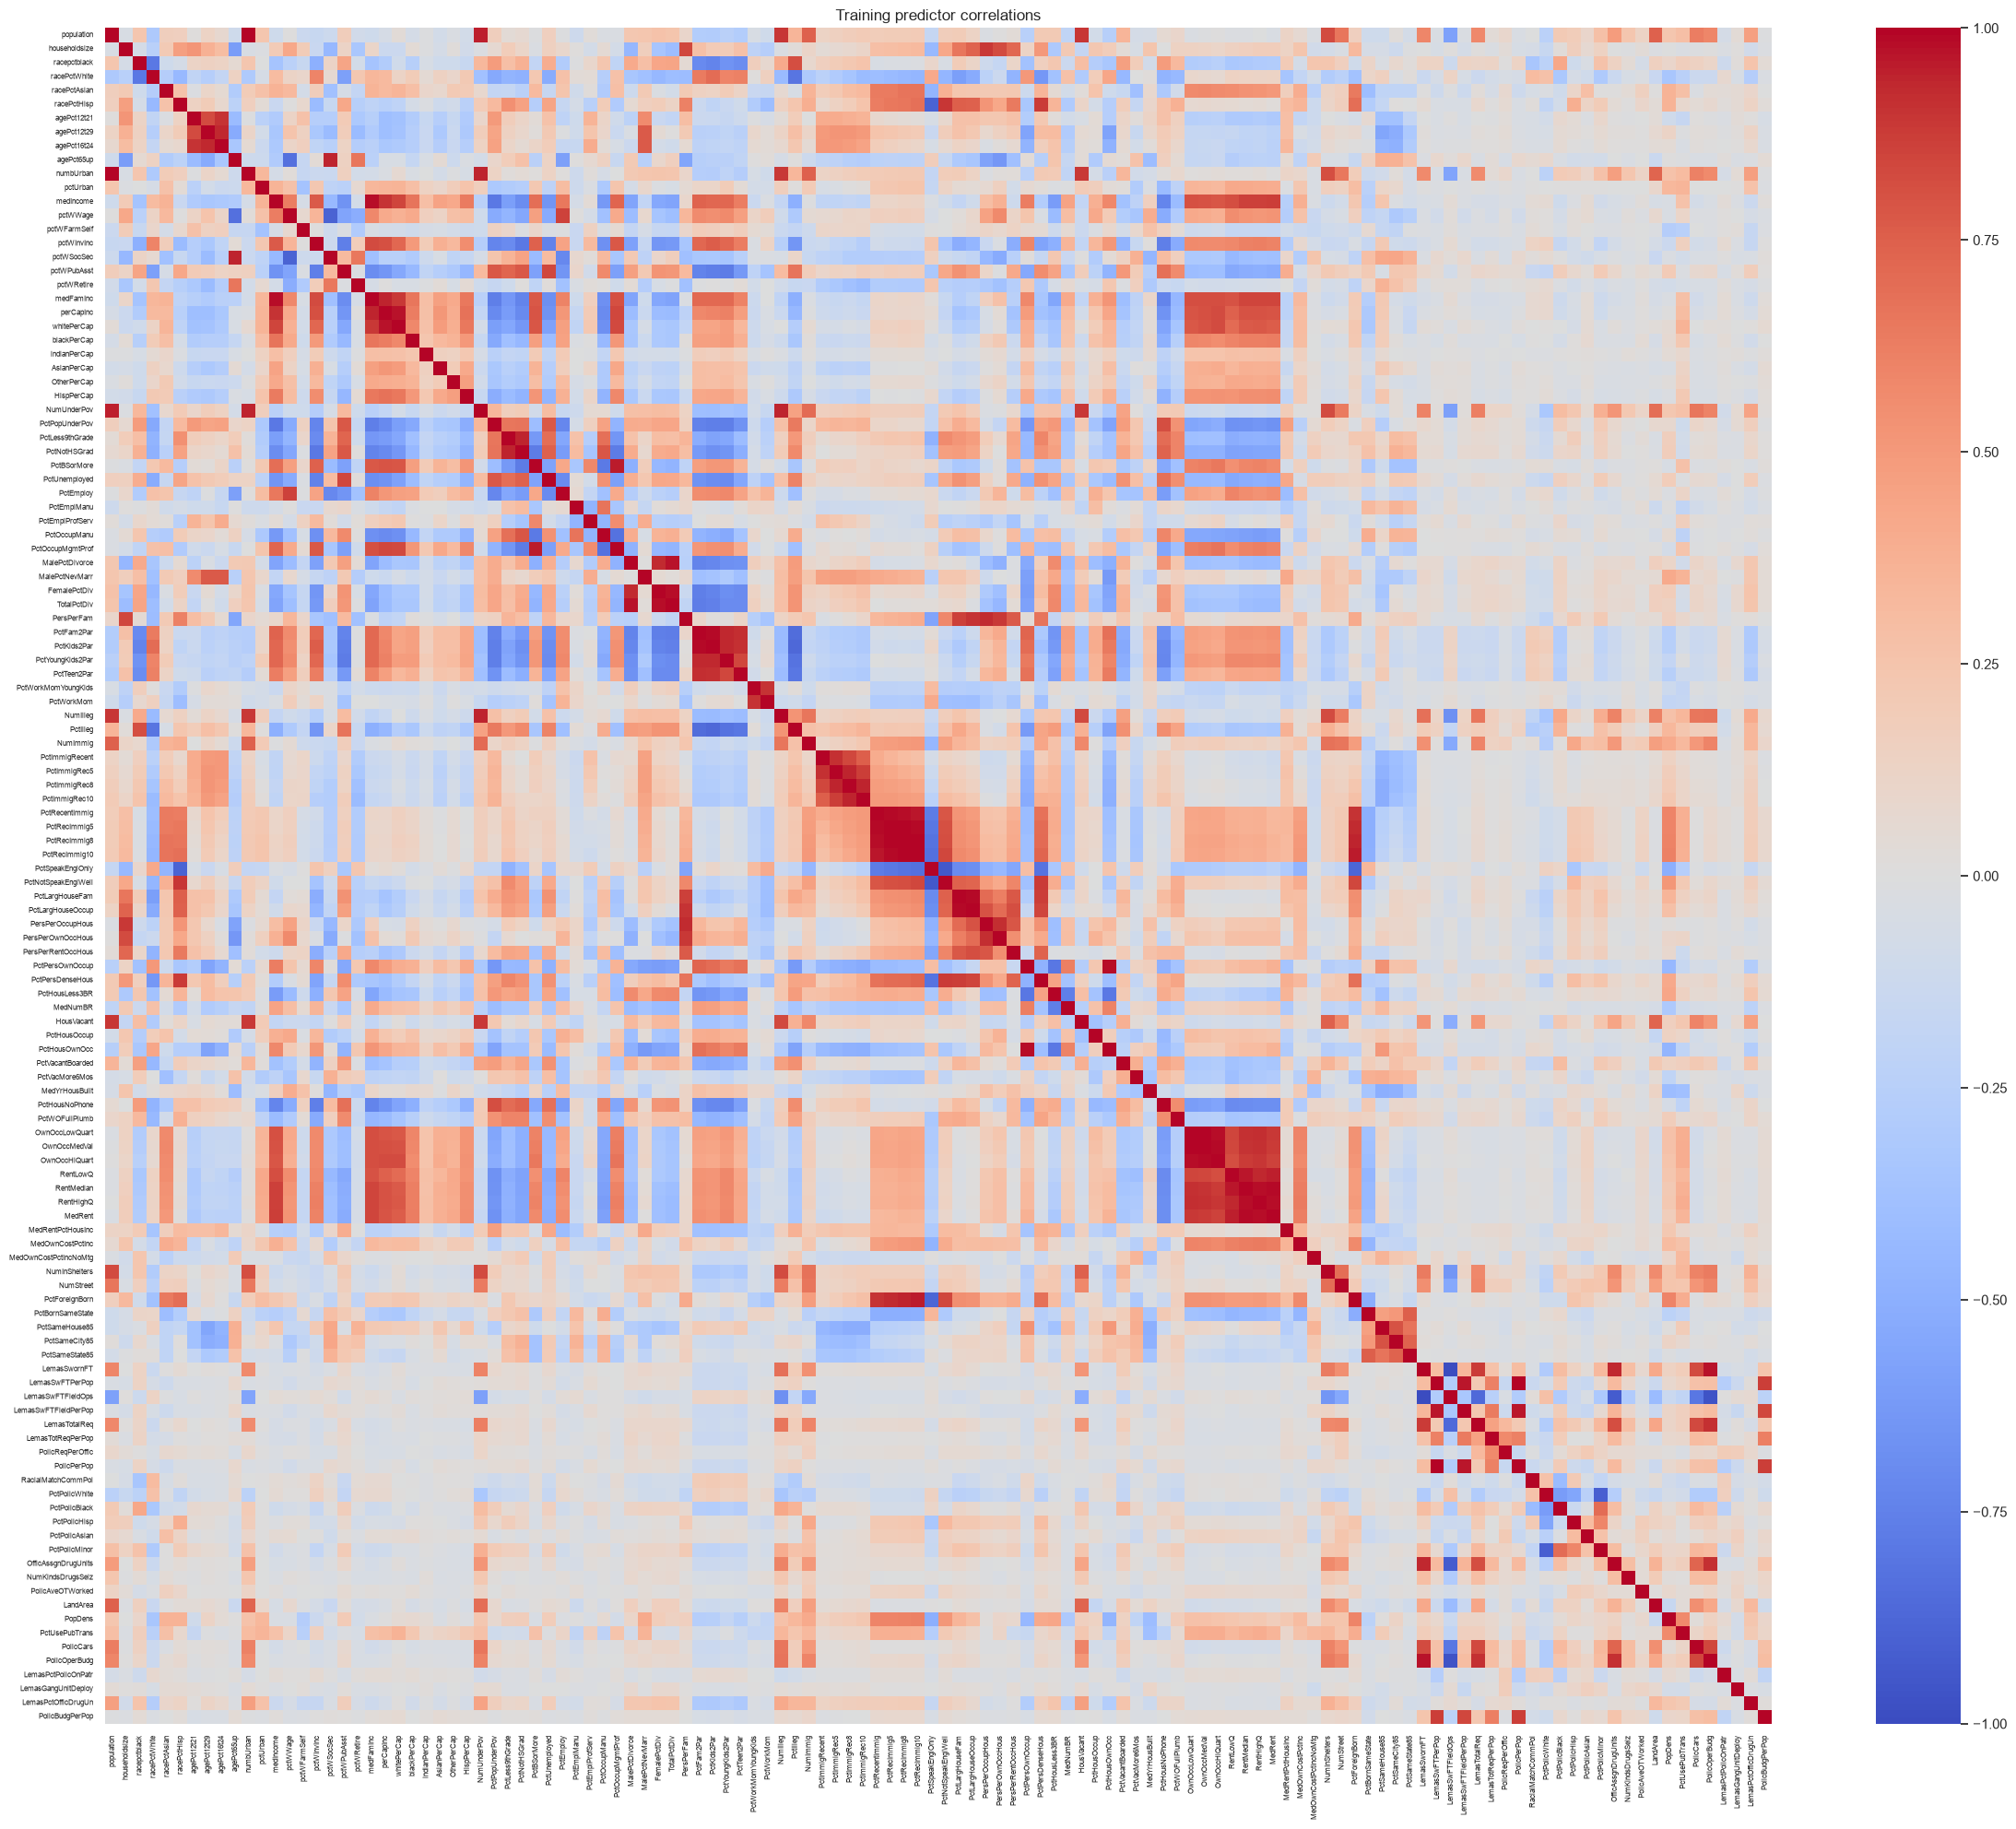

In [10]:
plt.figure(figsize=(24, 20))
sns.heatmap(train_plot.corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1,
            xticklabels=True, yticklabels=True)
plt.xticks(fontsize=6, rotation=90)
plt.yticks(fontsize=6)
plt.title("Training predictor correlations")
plt.tight_layout()
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [11]:
feature_cv = (train_plot.std(ddof=1) / train_plot.mean().replace(0, np.nan))
feature_cv = feature_cv.sort_values(ascending=False)
display(feature_cv.rename("CV").to_frame())

,CV
NumStreet,4.292923
NumInShelters,3.470952
NumIlleg,3.058964
NumImmig,2.926635
LemasPctOfficDrugUn,2.552946
NumUnderPov,2.342443
population,2.241105
numbUrban,2.038461
HousVacant,1.968467
LandArea,1.645408


### (e) Scatter plots and box plots for highest CV features

,CV
NumStreet,4.292923
NumInShelters,3.470952
NumIlleg,3.058964
NumImmig,2.926635
LemasPctOfficDrugUn,2.552946
NumUnderPov,2.342443
population,2.241105
numbUrban,2.038461
HousVacant,1.968467
LandArea,1.645408


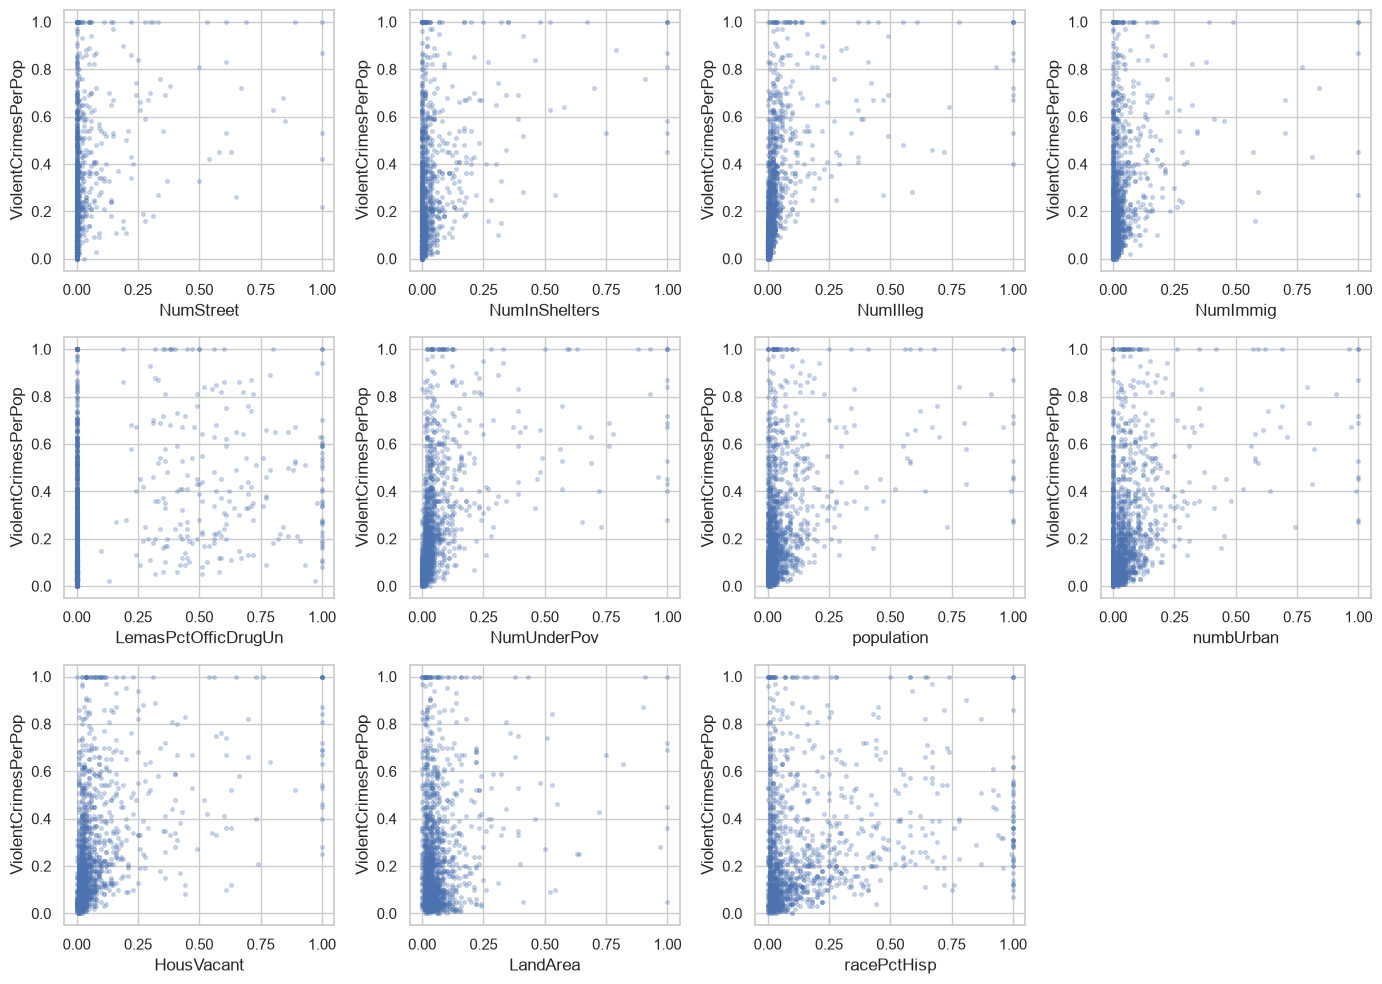

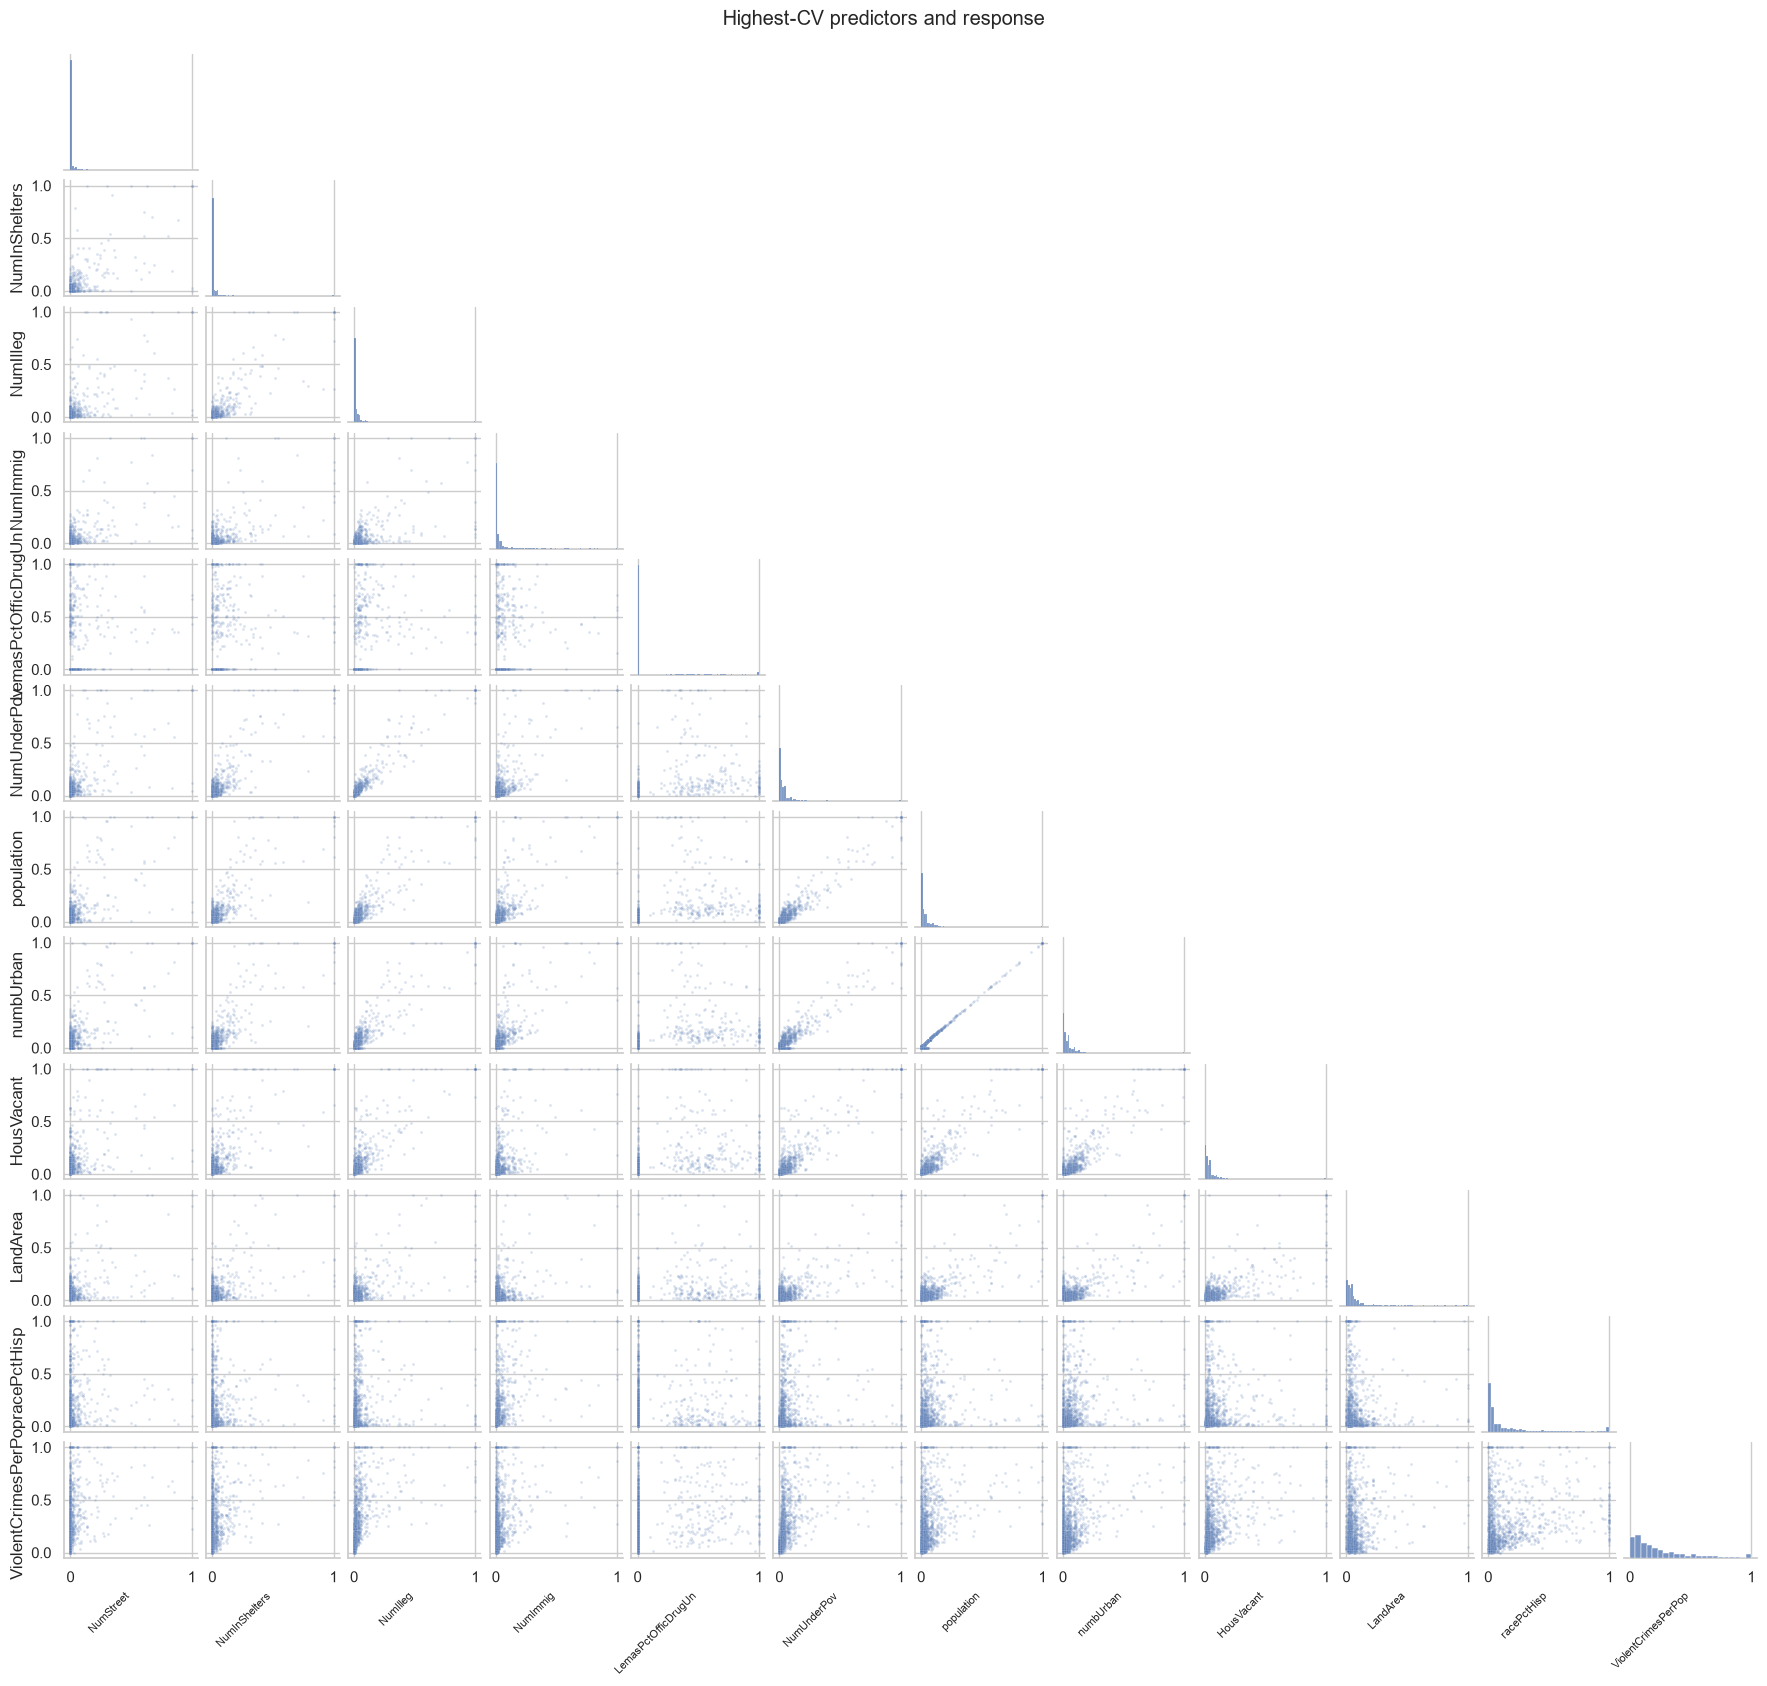

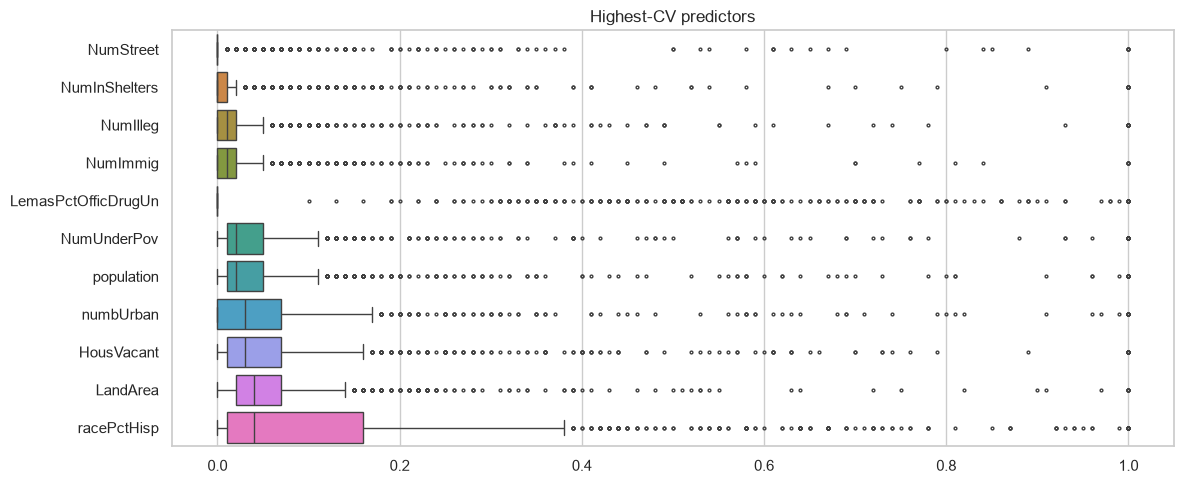

In [12]:
highest = feature_cv.head(int(np.sqrt(128))).index.tolist()
display(feature_cv.loc[highest].rename("CV").to_frame())
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, feature in zip(axes.flat, highest):
    ax.scatter(train_plot[feature], y_train, s=7, alpha=0.25)
    ax.set(xlabel=feature, ylabel=target)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

pair_data = train_plot[highest].assign(ViolentCrimesPerPop=y_train)
g = sns.pairplot(pair_data, corner=True, diag_kind="hist", height=1.5,
                 plot_kws={"s": 4, "alpha": 0.2})
for ax in g.axes[-1, :]:
    ax.set_xlabel(ax.get_xlabel(), rotation=45, ha="right", fontsize=8)
g.figure.subplots_adjust(bottom=0.15)
g.figure.suptitle("Highest-CV predictors and response", y=1.01)
plt.show()

plt.figure(figsize=(12, 5))
sns.boxplot(data=train_plot[highest], orient="h", fliersize=2)
plt.title("Highest-CV predictors")
plt.tight_layout()
plt.show()

The plots show skewed distributions and some possible relationships with crime.
However, scatter plots alone cannot show statistical significance. High CV is not
the same as a strong relationship with the response. We would need an appropriate
statistical test for significance and validation data to assess prediction.

### (f) Fit a linear model

In [13]:
results = []

def report(name, model):
    mse = mean_squared_error(y_test, model.predict(X_test))
    results.append({"Model": name, "Test MSE": mse, "Test RMSE": np.sqrt(mse)})
    print(f"{name}: test MSE = {mse:.6f}, RMSE = {np.sqrt(mse):.6f}")

ols = Pipeline([("imputer", SimpleImputer()), ("model", LinearRegression())])
ols.fit(X_train, y_train)
report("Least squares", ols)

Least squares: test MSE = 0.018142, RMSE = 0.134692


### (g) Fit a ridge regression model

In [14]:
ridge = GridSearchCV(Pipeline([
    ("imputer", SimpleImputer()), ("scaler", StandardScaler()), ("model", Ridge())]),
    {"model__alpha": np.logspace(-3, 4, 50)}, cv=cv, scoring="neg_mean_squared_error")
ridge.fit(X_train, y_train)
print("Best alpha:", ridge.best_params_["model__alpha"])
print("CV MSE:", -ridge.best_score_)
report("Ridge", ridge)

Best alpha: 71.96856730011514
CV MSE: 0.019160536679879586
Ridge: test MSE = 0.017555, RMSE = 0.132495


### (h) Fit a LASSO model

In [15]:
lasso_raw = GridSearchCV(Pipeline([
    ("imputer", SimpleImputer()), ("model", Lasso(max_iter=30000))]),
    {"model__alpha": np.logspace(-5, -1, 41)}, cv=cv, scoring="neg_mean_squared_error")
lasso_std = GridSearchCV(Pipeline([
    ("imputer", SimpleImputer()), ("scaler", StandardScaler()),
    ("model", Lasso(max_iter=30000))]),
    {"model__alpha": np.logspace(-5, -1, 41)}, cv=cv, scoring="neg_mean_squared_error")

selected_variables = {}
for name, model in [("LASSO original", lasso_raw), ("LASSO standardized", lasso_std)]:
    model.fit(X_train, y_train)
    selected = X.columns[model.best_estimator_.named_steps["model"].coef_ != 0].tolist()
    selected_variables[name] = selected
    print(name, "alpha:", model.best_params_["model__alpha"], "CV MSE:", -model.best_score_)
    print("Selected variables:", len(selected))
    print(", ".join(selected))
    report(name, model)
    print()

LASSO original alpha: 0.0001 CV MSE: 0.01901801996466272
Selected variables: 78
racepctblack, racePctAsian, agePct12t21, agePct12t29, agePct65up, pctUrban, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctBSorMore, PctEmploy, PctEmplManu, PctOccupManu, MalePctDivorce, MalePctNevMarr, FemalePctDiv, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRec10, PctRecImmig10, PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, RentLowQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet, PctForeignBorn, PctSameCity85, LemasSwFTFieldPerPop, LemasTotalReq, PolicReqPerOffic, RacialMatchCo

The original-feature LASSO selects 78 variables with alpha = 0.0001 and test
MSE = 0.017786. The standardized LASSO selects 76 variables with alpha = 0.000631
and test MSE = 0.017852. The original-feature version is slightly better on this
test set. Standardization changes the penalty's effect, but it does not guarantee
a lower test error.

### (i) Fit a PCR model

Best M: 93
CV MSE: 0.019480811204558083
PCR: test MSE = 0.018368, RMSE = 0.135527


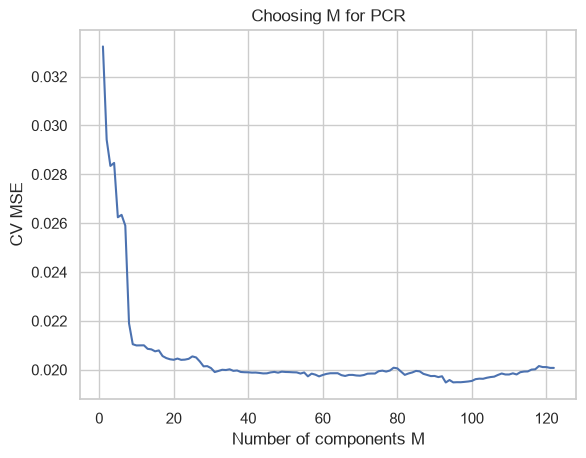

In [16]:
pcr = GridSearchCV(Pipeline([
    ("imputer", SimpleImputer()), ("scaler", StandardScaler()),
    ("pca", PCA(svd_solver="full")), ("model", LinearRegression())]),
    {"pca__n_components": list(range(1, X_train.shape[1] + 1))},
    cv=cv, scoring="neg_mean_squared_error")
pcr.fit(X_train, y_train)
print("Best M:", pcr.best_params_["pca__n_components"])
print("CV MSE:", -pcr.best_score_)
report("PCR", pcr)
plt.plot(range(1, X_train.shape[1] + 1), -pcr.cv_results_["mean_test_score"])
plt.xlabel("Number of components M")
plt.ylabel("CV MSE")
plt.title("Choosing M for PCR")
plt.show()

### (j) Fit a boosting tree

In [17]:
boost = GridSearchCV(Pipeline([
    ("imputer", SimpleImputer()),
    ("model", XGBRegressor(objective="reg:squarederror", booster="gbtree",
                           n_estimators=300, max_depth=3, learning_rate=0.05,
                           tree_method="hist", reg_lambda=1,
                           random_state=552, n_jobs=1))]),
    {"model__reg_alpha": [0, 0.001, 0.01, 0.1, 0.5, 1, 2, 5, 10]},
    cv=cv, scoring="neg_mean_squared_error")
boost.fit(X_train, y_train)
print("Best reg_alpha:", boost.best_params_["model__reg_alpha"])
print("CV MSE:", -boost.best_score_)
report("XGBoost", boost)

summary = pd.DataFrame(results).set_index("Model")
display(summary.round(6))

Best reg_alpha: 1
CV MSE: 0.019650923135211072
XGBoost: test MSE = 0.016293, RMSE = 0.127643


,Test MSE,Test RMSE
Model,,
Least squares,0.018142,0.134692
Ridge,0.017555,0.132495
LASSO original,0.017786,0.133364
LASSO standardized,0.017852,0.133610
PCR,0.018368,0.135527
XGBoost,0.016293,0.127643


XGBoost has the lowest observed test MSE (0.016293) in this comparison.
Ridge also improves on least squares. Standardizing LASSO does not improve its
test error here. All tuning choices use training CV, and these results apply to
this split and the stated parameter grids. The small differences between the
linear models do not establish statistical significance.